# Experimento Complementario: Entrenamiento con Perturbaciones Espaciales (Data Augmentation)
## Fase 1: Configuración del Entorno, Librerías y Reproducibilidad

### 1.1 Objetivo del Experimento
Tras comprobar en la prueba anterior que el modelo *Baseline* sufre una caída drástica de precisión (del 76,48% al 59,65%) cuando las imágenes de prueba son desplazadas o rotadas, en este notebook planteamos una nueva hipótesis experimental: **¿Es capaz una red neuronal densa (MLP) de adquirir invarianza espacial si se entrena directamente con imágenes perturbadas?**

Para responder a esta pregunta, entrenaremos la arquitectura `BaselineMLP128` desde cero aplicando transformaciones geométricas aleatorias (traslaciones y rotaciones) **tanto en el conjunto de entrenamiento (*Train*) como en el de evaluación (*Test*)**.

---

### 1.2 Descripción de las Librerías Utilizadas
- **`torch` y `torch.nn`:** Framework principal para la construcción de tensores, definición de capas lineales (`nn.Linear`), aplanamiento (`nn.Flatten`), regularización (`nn.Dropout`) y cálculo automático de gradientes (*Autograd*).
- **`torch.optim`:** Implementación del optimizador estocástico `Adam` para la actualización eficiente de los pesos.
- **`torchvision.transforms` y `torchvision.transforms.functional`:** Herramientas clave para este experimento. Permiten construir un pipeline de transformación al vuelo en memoria RAM aplicando rotaciones (`rotate`), traslaciones (`affine`) y relleno espejo (`pad`) sin necesidad de duplicar archivos en el disco duro.
- **`torch.utils.data.DataLoader`:** Gestión eficiente de lotes (*mini-batches*) optimizada para el procesamiento en CPU.
- **`sklearn.metrics` y `seaborn` / `matplotlib`:** Extracción de métricas cuantitativas (Precision, Recall, F1-Score) y visualización de la matriz de confusión y comparativas gráficas.

In [6]:
import os
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
from sklearn.metrics import classification_report, confusion_matrix

import cv2

# 1. Configuración del dispositivo de cómputo (CPU Intel Core i5)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[SETUP] Dispositivo de cómputo activo: {device.type.upper()}")

# 2. Fijación de semilla global para garantizar la reproducibilidad científica
SEED = 42

def set_seed(seed_value):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)

set_seed(SEED)
print(f"[SETUP] Semilla global establecida en: {SEED}")

[SETUP] Dispositivo de cómputo activo: CPU
[SETUP] Semilla global establecida en: 42


## Fase 2: Pipeline de Perturbación Espacial con OpenCV y Carga de Datos

### 2.1 Funcionamiento de la Función `PerturbacionOpenCV`
Para simular variaciones espaciales realistas y evitar que el modelo denso memorice coordenadas fijas de píxeles, se implementa un módulo de transformación geométrica basado en **OpenCV (`cv2`)**, aplicado dinámicamente en memoria RAM tanto en el conjunto de **entrenamiento (*Train*)** como en el de **evaluación (*Test*)**.

En cada iteración, el algoritmo convierte la imagen a un arreglo numérico de NumPy (`uint8`) y selecciona aleatoriamente una de cuatro configuraciones (25% de probabilidad cada una):
1. **Invariata:** La imagen conserva su encuadre original de $128 \times 128$ píxeles.
2. **Traslación pura:** Desplazamiento independiente en los ejes horizontal ($dx$) y vertical ($dy$) de hasta $\pm 16$ píxeles.
3. **Rotación + Zoom ligero:** Giro aleatorio entre $-18^\circ$ y $+18^\circ$ combinado con un factor de escala (*zoom*) controlado entre $0.92\times$ y $1.10\times$.
4. **Combinada completa:** Aplicación simultánea de rotación ($\pm 12^\circ$), zoom ligero ($0.95\times$ a $1.08\times$) y traslación ($\pm 12$ píxeles).

#### Parámetros Técnicos de OpenCV
- **Matriz de Transformación Afín (`cv2.getRotationMatrix2D`):** Calcula en una única matriz $2 \times 3$ el centro de rotación $(64, 64)$, el ángulo de giro y el factor de escala, sumando posteriormente los desplazamientos $(dx, dy)$ en la tercera columna.
- **Interpolación Bilineal (`cv2.INTER_LINEAR`):** Evita el efecto escalonado (*aliasing*) al rotar o escalar la cuadrícula de píxeles, preservando la nitidez visual.
- **Gestión de Bordes (`cv2.BORDER_REFLECT_101`):** Rellena automáticamente las zonas desplazadas reflejando de forma especular los píxeles adyacentes del contorno, eliminando franjas negras artificiales y manteniendo el rostro completo y centrado.

In [8]:
class PerturbacionOpenCV:
    """
    Aplica transformaciones afines (traslación, rotación y zoom ligero) utilizando OpenCV.
    Emplea interpolación bilineal y bordes reflejados (BORDER_REFLECT_101) para evitar
    artefactos negros y preservar la nitidez del rostro.
    """
    def __init__(self, max_shift_px=16, max_angle_deg=18, scale_range=(0.92, 1.10)):
        self.max_shift = max_shift_px
        self.max_angle = max_angle_deg
        self.scale_range = scale_range

    def __call__(self, img_pil):
        # 1. Convertir imagen PIL a arreglo NumPy (H, W, C) y redimensionar a 128x128
        img_np = np.array(img_pil)
        img_np = cv2.resize(img_np, (128, 128), interpolation=cv2.INTER_AREA)
        h, w = img_np.shape[:2]
        centro = (w // 2, h // 2)

        # 2. Elegir aleatoriamente el tipo de perturbación (25% de probabilidad cada una)
        opcion = random.choice(["invariata", "traslacion", "rotacion_zoom", "combinada"])

        if opcion == "invariata":
            return Image.fromarray(img_np)

        # Inicializar parámetros por defecto
        angulo = 0.0
        escala = 1.0
        dx, dy = 0, 0

        if opcion == "traslacion":
            dx = random.randint(-self.max_shift, self.max_shift)
            dy = random.randint(-self.max_shift, self.max_shift)

        elif opcion == "rotacion_zoom":
            angulo = random.uniform(-self.max_angle, self.max_angle)
            escala = random.uniform(self.scale_range[0], self.scale_range[1])

        elif opcion == "combinada":
            angulo = random.uniform(-12.0, 12.0)
            escala = random.uniform(0.95, 1.08)
            dx = random.randint(-12, 12)
            dy = random.randint(-12, 12)

        # 3. Construir la matriz de transformación afín 2x3 con OpenCV
        M = cv2.getRotationMatrix2D(centro, angulo, escala)
        # Añadir la traslación (dx, dy) en la última columna de la matriz
        M[0, 2] += dx
        M[1, 2] += dy

        # 4. Aplicar la transformación con interpolación bilineal y relleno espejo en bordes
        img_mod = cv2.warpAffine(
            img_np,
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REFLECT_101
        )

        # 5. Devolver como objeto PIL Image para continuar con el pipeline de PyTorch
        return Image.fromarray(img_mod)

# Pipeline completo: Perturbación OpenCV -> Tensor -> Normalización [-1, 1]
transform_perturbado = transforms.Compose([
    PerturbacionOpenCV(max_shift_px=16, max_angle_deg=18, scale_range=(0.92, 1.10)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

# Carga de conjuntos Train y Test (ambos con perturbación OpenCV activa)
DATASET_PATH = "./fase_2/secondo_archiviio/sample_10k/" 

train_dataset = datasets.ImageFolder(root=os.path.join(DATASET_PATH, "train"), transform=transform_perturbado)
test_dataset  = datasets.ImageFolder(root=os.path.join(DATASET_PATH, "test"),  transform=transform_perturbado)

print(f"[DATOS] Mapeo de clases: {train_dataset.class_to_idx}")
print(f"[DATOS] Muestras Train (OpenCV): {len(train_dataset)} | Muestras Test (OpenCV): {len(test_dataset)}")

# DataLoaders optimizados para Intel Core i5
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

[DATOS] Mapeo de clases: {'fake': 0, 'real': 1}
[DATOS] Muestras Train (OpenCV): 16022 | Muestras Test (OpenCV): 4005


### 2.3 Inspección Visual de las Perturbaciones en el Conjunto de Entrenamiento
Antes de iniciar el entrenamiento, visualizamos una muestra aleatoria de imágenes del *train set* comparando su estado original frente a la versión modificada que recibirá la red neuronal en cada época.

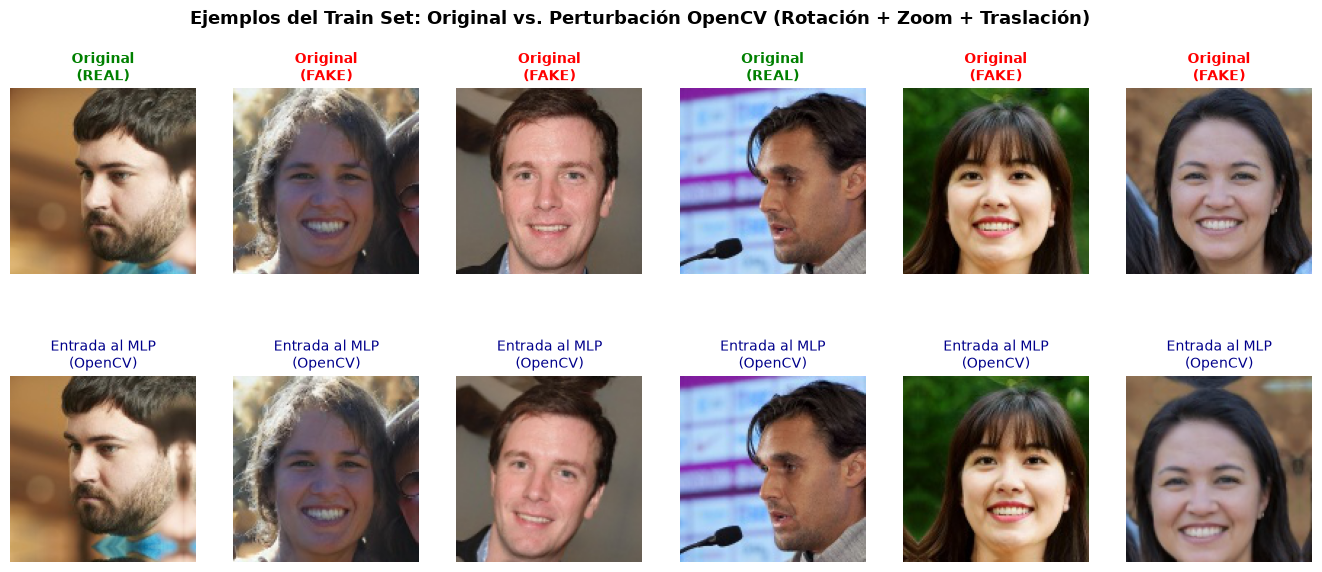

In [9]:
# Selección de 6 imágenes aleatorias del conjunto de entrenamiento
num_ejemplos = 6
indices_muestra = random.sample(range(len(train_dataset)), num_ejemplos)

perturbador_vis = PerturbacionOpenCV(max_shift_px=16, max_angle_deg=18, scale_range=(0.92, 1.10))

fig, axes = plt.subplots(2, num_ejemplos, figsize=(2.8 * num_ejemplos, 6.5))
fig.suptitle("Ejemplos del Train Set: Original vs. Perturbación OpenCV (Rotación + Zoom + Traslación)", fontsize=13, fontweight="bold")

for col, idx in enumerate(indices_muestra):
    ruta_img, label_idx = train_dataset.samples[idx]
    clase_nombre = train_dataset.classes[label_idx].upper()
    color_etiqueta = "red" if clase_nombre == "FAKE" else "green"
    
    # Imagen original
    img_orig = Image.open(ruta_img).convert("RGB").resize((128, 128))
    # Imagen modificada con OpenCV
    img_mod = perturbador_vis(img_orig)
    
    # Fila 1: Original
    axes[0, col].imshow(img_orig)
    axes[0, col].set_title(f"Original\n({clase_nombre})", color=color_etiqueta, fontsize=10, fontweight="bold")
    axes[0, col].axis("off")
    
    # Fila 2: Modificada
    axes[1, col].imshow(img_mod)
    axes[1, col].set_title("Entrada al MLP\n(OpenCV)", color="darkblue", fontsize=10)
    axes[1, col].axis("off")

plt.subplots_adjust(hspace=0.35)
plt.show()

## Fase 3: Definición de la Arquitectura `BaselineMLP128`

### 3.1 Estructura del Modelo
Para mantener una comparación rigurosa con el experimento original sin perturbaciones, conservamos exactamente la misma arquitectura densa:
- **Entrada:** Tensor de imagen RGB de $128 \times 128 \times 3$ aplanado en un vector unidimensional de **49.152 características** (`nn.Flatten`).
- **Capas Ocultas:** Dos capas completamente conectadas (`nn.Linear`) de **128** y **64** neuronas con activación no lineal `ReLU`.
- **Regularización:** Capa `nn.Dropout(p=0.3)` tras la primera proyección densa para mitigar el sobreajuste (*overfitting*) y forzar redundancia en los pesos frente a las variaciones espaciales.
- **Salida:** Capa lineal final de **2 neuronas** correspondiente a las clases `fake` y `real`.

In [10]:
class BaselineMLP128(nn.Module):
    def __init__(self):
        super(BaselineMLP128, self).__init__()
        # Aplanamiento: 128 * 128 * 3 = 49,152 características de entrada
        self.flatten = nn.Flatten()
        
        self.classifier = nn.Sequential(
            nn.Linear(128 * 128 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.classifier(x)

# Instanciar el modelo desde cero (pesos aleatorios) y mover a CPU
model = BaselineMLP128().to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\n[ARQUITECTURA] Total de parámetros entrenables: {total_params:,}")

BaselineMLP128(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=49152, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=2, bias=True)
  )
)

[ARQUITECTURA] Total de parámetros entrenables: 6,299,970


## Fase 4: Entrenamiento con Data Augmentation Espacial (OpenCV)

### 4.1 Configuración del Optimización
Entrenamos la red durante **8 épocas** utilizando la función de pérdida `CrossEntropyLoss` y el optimizador `Adam` (`lr=0.001`). Al aplicar `PerturbacionOpenCV` dinámicamente en cada lote, la red nunca observa exactamente la misma disposición de píxeles entre épocas, obligándola a buscar patrones más robustos que las coordenadas estáticas.

[ENTRENAMIENTO] Iniciando entrenamiento con perturbaciones OpenCV en CPU...
Época 01/08 | Tiempo: 72.7s | Pérdida: 0.8011 | Precisión Train: 55.75%
Época 02/08 | Tiempo: 57.6s | Pérdida: 0.6752 | Precisión Train: 58.52%
Época 03/08 | Tiempo: 61.0s | Pérdida: 0.6623 | Precisión Train: 60.26%
Época 04/08 | Tiempo: 58.6s | Pérdida: 0.6527 | Precisión Train: 61.22%
Época 05/08 | Tiempo: 58.7s | Pérdida: 0.6444 | Precisión Train: 62.41%
Época 06/08 | Tiempo: 58.5s | Pérdida: 0.6402 | Precisión Train: 63.09%
Época 07/08 | Tiempo: 65.0s | Pérdida: 0.6382 | Precisión Train: 63.78%
Época 08/08 | Tiempo: 61.2s | Pérdida: 0.6349 | Precisión Train: 63.74%

[ENTRENAMIENTO] Finalizado en 493.37 segundos.


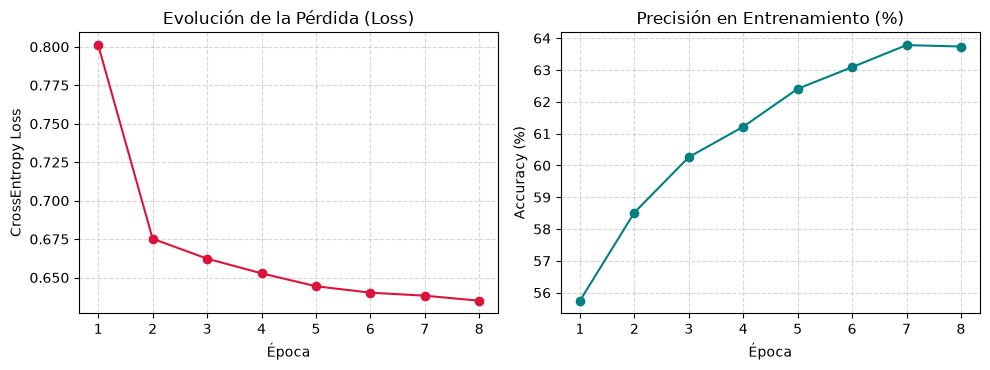

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 8
history_loss = []
history_acc = []

start_total_time = time.time()
print(f"[ENTRENAMIENTO] Iniciando entrenamiento con perturbaciones OpenCV en {device.type.upper()}...")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    epoch_start = time.time()
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    epoch_duration = time.time() - epoch_start
    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    
    history_loss.append(epoch_loss)
    history_acc.append(epoch_acc)
    
    print(f"Época {epoch+1:02d}/{EPOCHS:02d} | Tiempo: {epoch_duration:.1f}s | "
          f"Pérdida: {epoch_loss:.4f} | Precisión Train: {epoch_acc:.2f}%")

total_training_time = time.time() - start_total_time
print(f"\n[ENTRENAMIENTO] Finalizado en {total_training_time:.2f} segundos.")

# Visualización rápida de la curva de aprendizaje
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(range(1, EPOCHS+1), history_loss, marker='o', color='crimson')
ax1.set_title("Evolución de la Pérdida (Loss)")
ax1.set_xlabel("Época")
ax1.set_ylabel("CrossEntropy Loss")
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(range(1, EPOCHS+1), history_acc, marker='o', color='teal')
ax2.set_title("Precisión en Entrenamiento (%)")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Fase 5: Evaluación sobre el Conjunto de Test Perturbado y Exportación

### 5.1 Análisis de Resultados
Evaluamos el modelo recién entrenado sobre las **4.005 imágenes de prueba** sometidas igualmente a `PerturbacionOpenCV`. Observamos si el entrenamiento con aumentación de datos permite recuperar la precisión perdida frente al test perturbado (59,65%) o si la falta de extracción local de características sigue limitando el rendimiento de la arquitectura densa.

[TEST] Evaluando rendimiento en 4005 imágenes de prueba perturbadas...

[EFICIENCIA] Latencia media de inferencia: 0.2310 ms/imagen

[MÉTRICAS] Informe de Clasificación (Train & Test Perturbados):
              precision    recall  f1-score   support

        fake     0.6203    0.7760    0.6895      2000
        real     0.7019    0.5262    0.6015      2005

    accuracy                         0.6509      4005
   macro avg     0.6611    0.6511    0.6455      4005
weighted avg     0.6612    0.6509    0.6454      4005



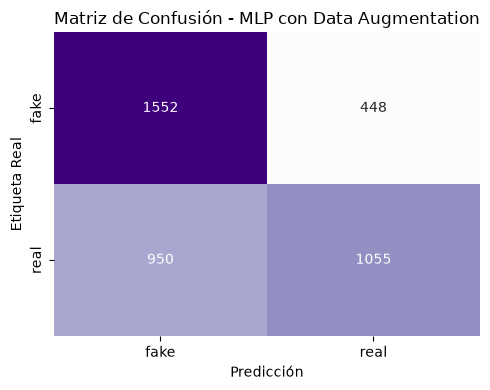


[EXPORTACIÓN] Pesos guardados exitosamente en 'baseline_mlp_128_img_modificate.pth'


In [12]:
model.eval()
all_preds = []
all_labels = []
inference_times = []

print(f"[TEST] Evaluando rendimiento en {len(test_dataset)} imágenes de prueba perturbadas...")

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        
        t0 = time.perf_counter()
        outputs = model(images)
        t1 = time.perf_counter()
        
        batch_size_curr = images.size(0)
        inference_times.append((t1 - t0) / batch_size_curr)
        
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 1. Latencia media de inferencia
avg_latency_ms = np.mean(inference_times) * 1000
print(f"\n[EFICIENCIA] Latencia media de inferencia: {avg_latency_ms:.4f} ms/imagen")

# 2. Informe formal de métricas
class_names = list(train_dataset.class_to_idx.keys())
print("\n[MÉTRICAS] Informe de Clasificación (Train & Test Perturbados):")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 3. Matriz de Confusión
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta Real")
plt.title("Matriz de Confusión - MLP con Data Augmentation")
plt.tight_layout()
plt.show()

# 4. Guardado de los nuevos pesos entrenados
SAVE_PATH = "baseline_mlp_128_img_modificate.pth"
torch.save(model.state_dict(), SAVE_PATH)
print(f"\n[EXPORTACIÓN] Pesos guardados exitosamente en '{SAVE_PATH}'")

## Conclusiones del Experimento con Data Augmentation

1. **Recuperación parcial frente a perturbaciones:** Entrenar el modelo `BaselineMLP128` directamente con transformaciones geométricas de OpenCV permite elevar la precisión en el conjunto de prueba perturbado desde el **59,65%** hasta el **65,09%**, recuperando la capacidad de detectar imágenes sintéticas desplazadas o rotadas (`Recall Fake = 77,60%`).
2. **Insuficiencia estructural del perceptrón multicapa (MLP):** A pesar de la aumentación de datos, el modelo queda **11,39 puntos porcentuales por debajo** de su rendimiento sobre imágenes alineadas (76,48%) y sufre un elevado número de falsos positivos (`950 imágenes reales clasificadas como fake`).
3. **Justificación metodológica para los siguientes niveles:** Este resultado confirma de forma definitiva que la **invarianza espacial** no puede lograrse eficientemente en redes densas aplanadas mediante *Data Augmentation*. Para resolver el problema con rigor se requiere extraer características locales invariantes a la posición (como gradientes **HOG** y micro-texturas **LBP** en el Tier 2) o emplear pesos compartidos mediante **Redes Convolucionales (CNN)** en el Tier 3.